In [1]:
from pymongo import MongoClient

### Ejercicio 1

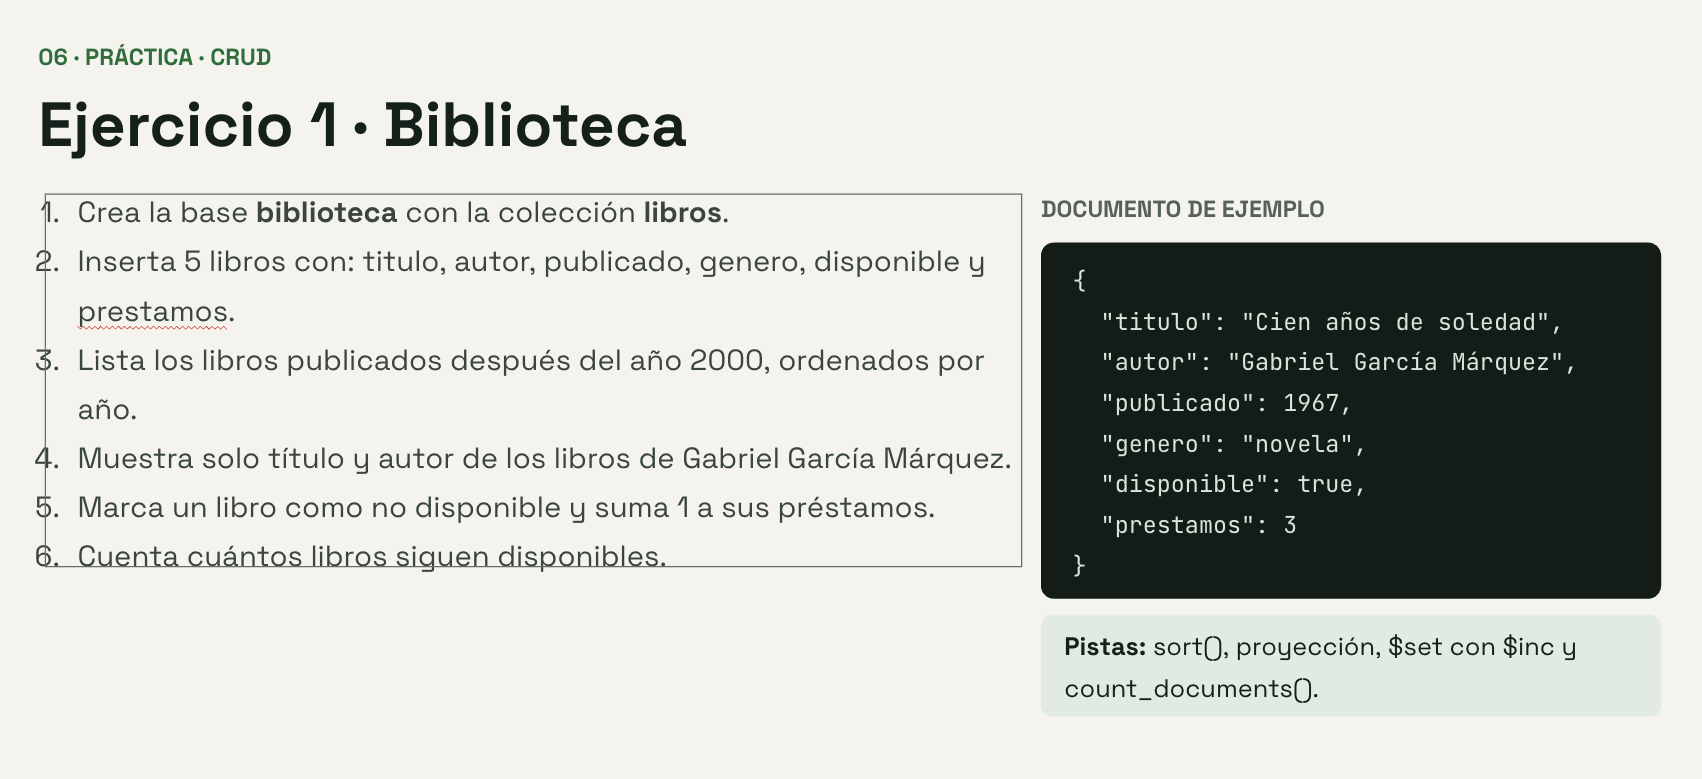

In [2]:
client = MongoClient("mongodb://localhost:27017")
biblioteca_db = client["biblioteca"]
libros = biblioteca_db["libros"]

In [3]:
libros.insert_many(
    [
        {
            "titulo": "Cien años de soledad",
            "autor": "Gabriel García Márquez",
            "publicado": 1967,
            "genero": "novela",
            "disponible": True,
            "prestamos": 3
        },
        {
            "titulo": "El psicoanalista",
            "autor": "John Katzenbach",
            "publicado": 2003,
            "genero": "thriller",
            "disponible": True,
            "prestamos": 2
        },
        {
            "titulo": "Lituma en los Andes",
            "autor": "Mario Vargas Llosa",
            "publicado": 1970,
            "genero": "novela",
            "disponible": False,
            "prestamos": 5
        },
        {
            "titulo": "La senda del perdedor",
            "autor": "Charles Bukowski",
            "publicado": 1980,
            "genero": "novela negra",
            "disponible": True,
            "prestamos": 1
        },
        {
            "titulo": "El coronel no tiene quien le escriba",
            "autor": "Gabriel García Márquez",
            "publicado": 1965,
            "genero": "novela",
            "disponible": True,
            "prestamos": 4
        }
    ]
)

InsertManyResult([ObjectId('6adac12989c6c9a50ad58730'), ObjectId('6adac12989c6c9a50ad58731'), ObjectId('6adac12989c6c9a50ad58732'), ObjectId('6adac12989c6c9a50ad58733'), ObjectId('6adac12989c6c9a50ad58734')], acknowledged=True)

In [4]:
list(libros.find())

[{'_id': ObjectId('6adac12989c6c9a50ad58730'),
  'titulo': 'Cien años de soledad',
  'autor': 'Gabriel García Márquez',
  'publicado': 1967,
  'genero': 'novela',
  'disponible': True,
  'prestamos': 3},
 {'_id': ObjectId('6adac12989c6c9a50ad58731'),
  'titulo': 'El psicoanalista',
  'autor': 'John Katzenbach',
  'publicado': 2003,
  'genero': 'thriller',
  'disponible': True,
  'prestamos': 2},
 {'_id': ObjectId('6adac12989c6c9a50ad58732'),
  'titulo': 'Lituma en los Andes',
  'autor': 'Mario Vargas Llosa',
  'publicado': 1970,
  'genero': 'novela',
  'disponible': False,
  'prestamos': 5},
 {'_id': ObjectId('6adac12989c6c9a50ad58733'),
  'titulo': 'La senda del perdedor',
  'autor': 'Charles Bukowski',
  'publicado': 1980,
  'genero': 'novela negra',
  'disponible': True,
  'prestamos': 1},
 {'_id': ObjectId('6adac12989c6c9a50ad58734'),
  'titulo': 'El coronel no tiene quien le escriba',
  'autor': 'Gabriel García Márquez',
  'publicado': 1965,
  'genero': 'novela',
  'disponible': T

In [5]:
for libro in libros.find({"publicado": {"$gt": 2000}}).sort("publicado", 1):
    print(libro)

{'_id': ObjectId('6adac12989c6c9a50ad58731'), 'titulo': 'El psicoanalista', 'autor': 'John Katzenbach', 'publicado': 2003, 'genero': 'thriller', 'disponible': True, 'prestamos': 2}


In [6]:
for libro in libros.find(
    {"autor": "Gabriel García Márquez"},
    {"titulo": 1, "autor": 1, "_id": 0}
):
    print(libro)

{'titulo': 'Cien años de soledad', 'autor': 'Gabriel García Márquez'}
{'titulo': 'El coronel no tiene quien le escriba', 'autor': 'Gabriel García Márquez'}


In [7]:
libros.find_one({"titulo": "Cien años de soledad"})

{'_id': ObjectId('6adac12989c6c9a50ad58730'),
 'titulo': 'Cien años de soledad',
 'autor': 'Gabriel García Márquez',
 'publicado': 1967,
 'genero': 'novela',
 'disponible': True,
 'prestamos': 3}

In [9]:
libros.update_one(
    {"titulo": "Cien años de soledad"},
    {
        "$set": {"disponible": False},
        "$inc": {"prestamos": 1}
    }
)

libros.find_one({"titulo": "Cien años de soledad"})

{'_id': ObjectId('6adac12989c6c9a50ad58730'),
 'titulo': 'Cien años de soledad',
 'autor': 'Gabriel García Márquez',
 'publicado': 1967,
 'genero': 'novela',
 'disponible': False,
 'prestamos': 4}

In [11]:
list(libros.find({}))

[{'_id': ObjectId('6adac12989c6c9a50ad58730'),
  'titulo': 'Cien años de soledad',
  'autor': 'Gabriel García Márquez',
  'publicado': 1967,
  'genero': 'novela',
  'disponible': False,
  'prestamos': 4},
 {'_id': ObjectId('6adac12989c6c9a50ad58731'),
  'titulo': 'El psicoanalista',
  'autor': 'John Katzenbach',
  'publicado': 2003,
  'genero': 'thriller',
  'disponible': True,
  'prestamos': 2},
 {'_id': ObjectId('6adac12989c6c9a50ad58732'),
  'titulo': 'Lituma en los Andes',
  'autor': 'Mario Vargas Llosa',
  'publicado': 1970,
  'genero': 'novela',
  'disponible': False,
  'prestamos': 5},
 {'_id': ObjectId('6adac12989c6c9a50ad58733'),
  'titulo': 'La senda del perdedor',
  'autor': 'Charles Bukowski',
  'publicado': 1980,
  'genero': 'novela negra',
  'disponible': True,
  'prestamos': 1},
 {'_id': ObjectId('6adac12989c6c9a50ad58734'),
  'titulo': 'El coronel no tiene quien le escriba',
  'autor': 'Gabriel García Márquez',
  'publicado': 1965,
  'genero': 'novela',
  'disponible': 

In [12]:
libros.count_documents({"disponible": True})

3

### Ejercicio 2

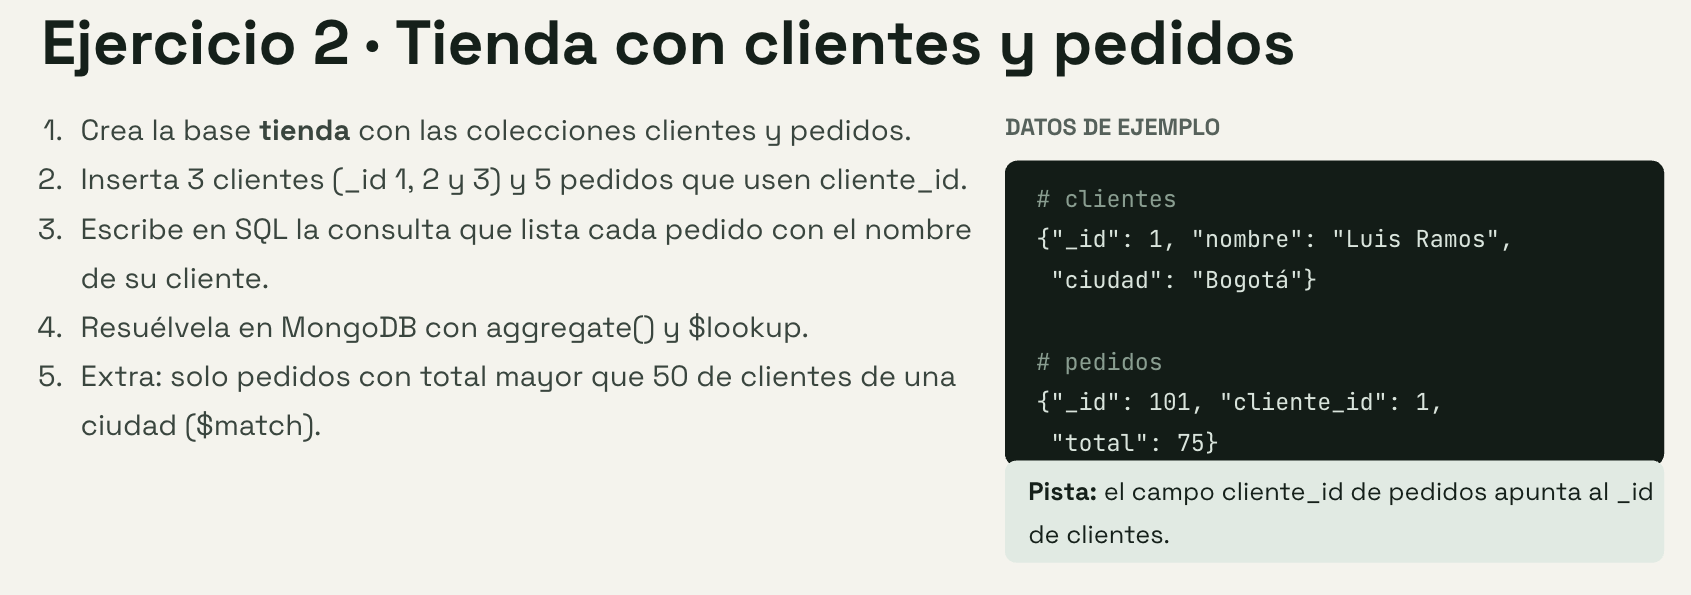

In [13]:
tienda_db = client["tienda"]
clientes = tienda_db["clientes"]
pedidos = tienda_db["pedidos"]

In [17]:
clientes.insert_many(
    [
        {"_id": 1, "nombre": "Luis Ramos", "ciudad": "Bogotá"},
        {"_id": 2, "nombre": "Ana Torres", "ciudad": "Lima"},
        {"_id": 3, "nombre": "María Paz", "ciudad": "Madrid"}
    ]
)

pedidos.insert_many(
    [
        {"_id": 101, "cliente_id": 1, "total": 75},
        {"_id": 102, "cliente_id": 2, "total": 80},
        {"_id": 103, "cliente_id": 3, "total": 90},
        {"_id": 104, "cliente_id": 2, "total": 30},
        {"_id": 105, "cliente_id": 3, "total": 100},
    ]
)

InsertManyResult([101, 102, 103, 104, 105], acknowledged=True)

In [ ]:
# SELECT p._id, c.nombre, p.total
# FROM pedidos AS p
# LEFT JOIN clientes AS c
# ON p.cliente_id = c._id

In [19]:
resultado = pedidos.aggregate(
    [
        {
            "$lookup": {
                "from": "clientes",
                "localField": "cliente_id",
                "foreignField": "_id",
                "as": "cliente"
            }
        },
        {"$unwind": "$cliente"},
        {"$project": {"total": 1, "nombre": "$cliente.nombre"}}
    ]
)

for r in resultado:
    print(r)

{'_id': 101, 'total': 75, 'nombre': 'Luis Ramos'}
{'_id': 102, 'total': 80, 'nombre': 'Ana Torres'}
{'_id': 103, 'total': 90, 'nombre': 'María Paz'}
{'_id': 104, 'total': 30, 'nombre': 'Ana Torres'}
{'_id': 105, 'total': 100, 'nombre': 'María Paz'}


In [23]:
resultado = pedidos.aggregate(
    [
        {
            "$lookup": {
                "from": "clientes",
                "localField": "cliente_id",
                "foreignField": "_id",
                "as": "cliente"
            }
        },
        {"$unwind": "$cliente"},
        {"$match": {"total": {"$gt": 50}, "cliente.ciudad": "Lima"}},
        {"$project": {"total": 1, "nombre": "$cliente.nombre"}}
    ]
)

for r in resultado:
    print(r)

{'_id': 102, 'total': 80, 'nombre': 'Ana Torres'}
